# COS80027 Machine Learning – Assignment 2
## Customer Segmentation using K-Means and DBSCAN

## Task 1 – Data Loading and Exploration
### 1.1 Load and Clean Data

In [1]:
# 1.1 – Load and inspect the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv("data/customers.csv")

# Basic inspection
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check for duplicates
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Drop CustomerID as it is not a feature for clustering
df.drop(columns=['CustomerID'], inplace=True)
print("\nCleaned dataset shape:", df.shape)


Shape: (200, 5)

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (200, 4)


### 1.2 Descriptive Statistical Analysis

In [2]:
# 1.2 – Descriptive statistics
print("Summary statistics for numerical features:")
display(df.describe())

# Gender distribution
print("\nGender distribution:")
print(df['Gender'].value_counts())


Summary statistics for numerical features:


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000



Gender distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


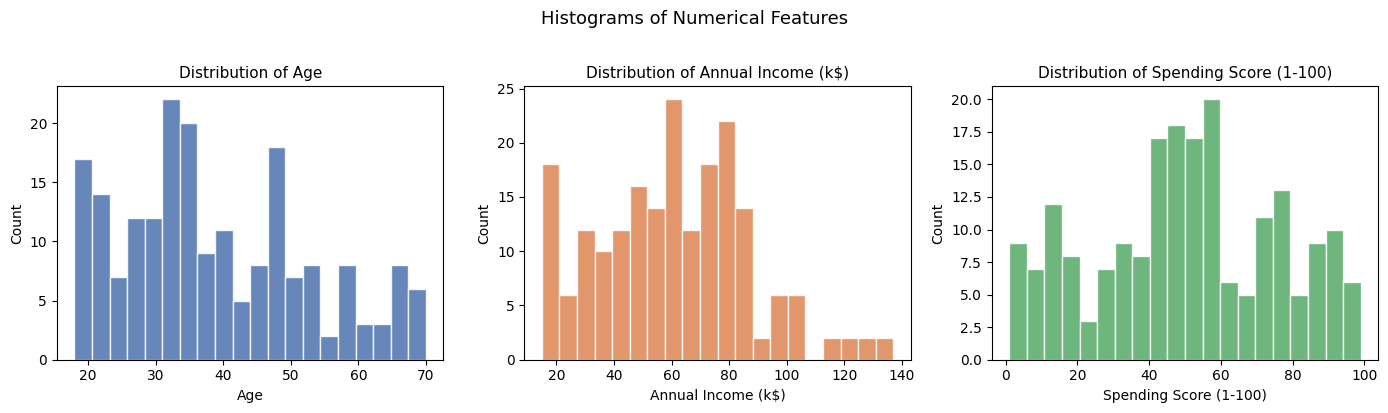

In [3]:
# 1.2 – Distribution plots for numerical features
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
num_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
colors = ['#4C72B0', '#DD8452', '#55A868']

for ax, col, color in zip(axes, num_features, colors):
    ax.hist(df[col], bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(f'Distribution of {col}', fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.suptitle('Histograms of Numerical Features', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


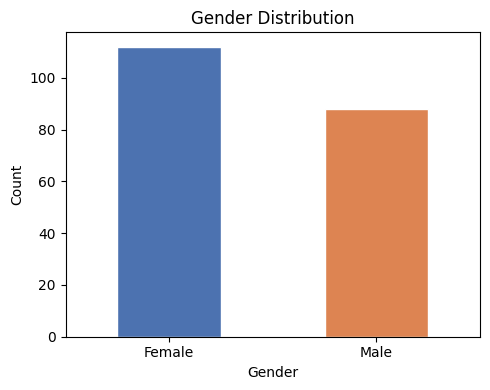

In [4]:
# 1.2 – Gender distribution bar plot
fig, ax = plt.subplots(figsize=(5, 4))
df['Gender'].value_counts().plot(kind='bar', ax=ax,
                                  color=['#4C72B0', '#DD8452'], edgecolor='white')
ax.set_title('Gender Distribution')
ax.set_xlabel('Gender')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()


### 1.3 Correlations and Dimensionality Reduction

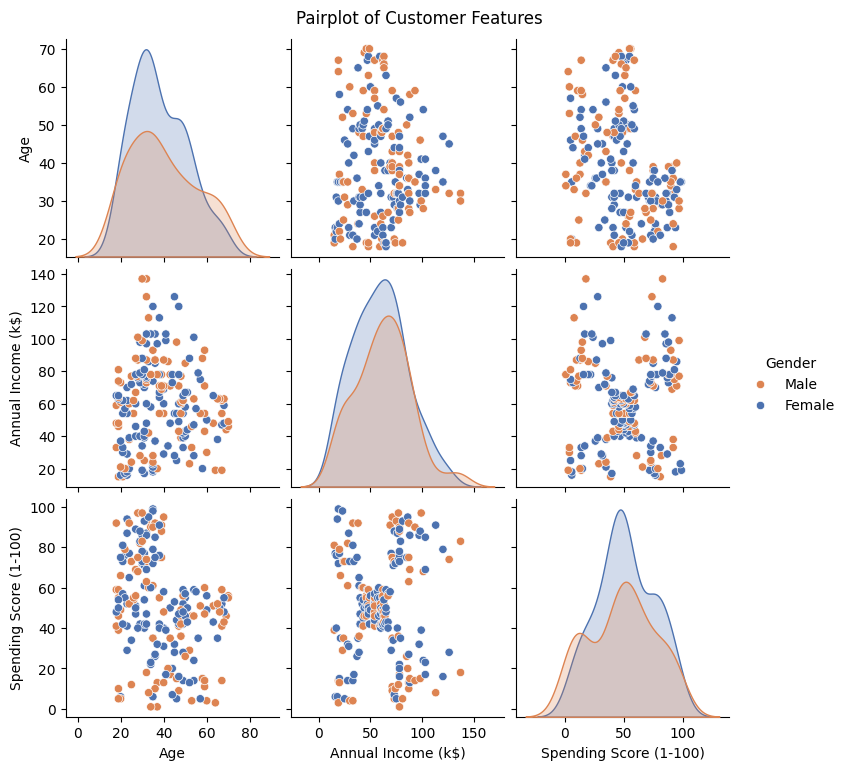

In [5]:
# 1.3 – Pairplot to visualise pairwise relationships
pair_df = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender']]
g = sns.pairplot(pair_df, hue='Gender',
                 palette={'Female': '#4C72B0', 'Male': '#DD8452'})
g.fig.suptitle('Pairplot of Customer Features', y=1.02)
plt.show()


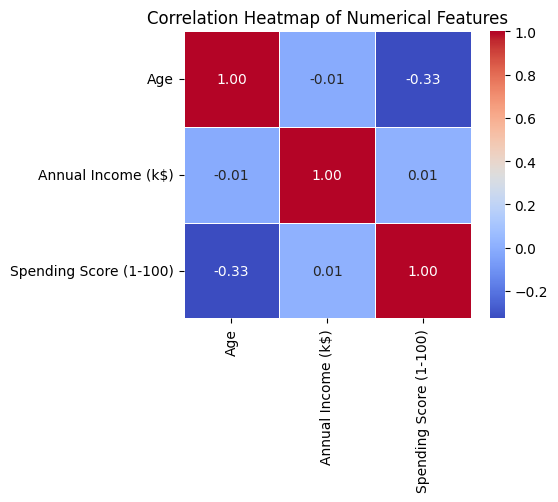

Correlation matrix:
                             Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.000000           -0.012398               -0.327227
Annual Income (k$)     -0.012398            1.000000                0.009903
Spending Score (1-100) -0.327227            0.009903                1.000000


In [6]:
# 1.3 – Pearson correlation heatmap
num_df = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

print("Correlation matrix:")
print(num_df.corr())


Explained variance per component:
  PC1: 33.69%  (cumulative: 33.69%)
  PC2: 26.23%  (cumulative: 59.92%)
  PC3: 23.26%  (cumulative: 83.18%)
  PC4: 16.82%  (cumulative: 100.00%)


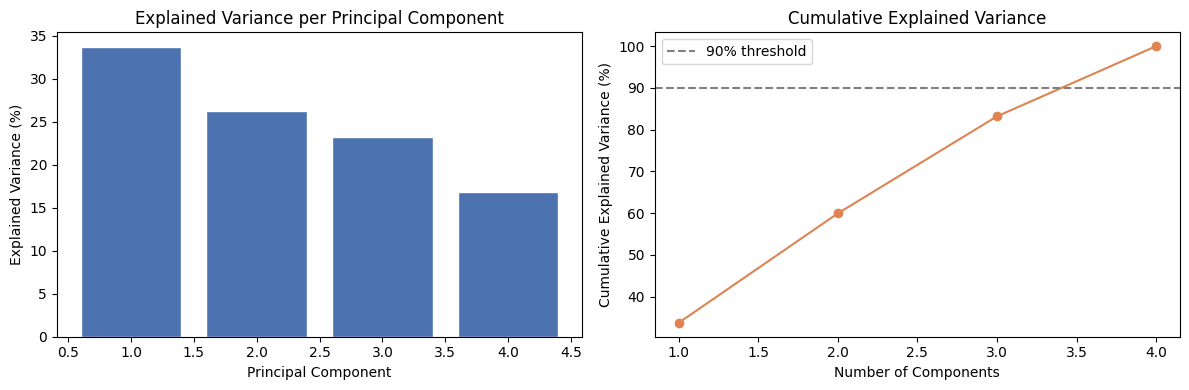

In [7]:
# 1.3 – PCA for dimensionality reduction
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

# Encode gender and scale all features
df_enc = df.copy()
df_enc['Gender'] = LabelEncoder().fit_transform(df_enc['Gender'])  # Female=0, Male=1

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_enc)

# Fit PCA on all 4 features
pca_full = PCA()
pca_full.fit(X_scaled)
ev  = pca_full.explained_variance_ratio_
cum_ev = np.cumsum(ev)

print("Explained variance per component:")
for i, (e, c) in enumerate(zip(ev, cum_ev)):
    print(f"  PC{i+1}: {e*100:.2f}%  (cumulative: {c*100:.2f}%)")

# Plot explained variance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, len(ev)+1), ev*100, color='#4C72B0', edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Explained Variance per Principal Component')

axes[1].plot(range(1, len(cum_ev)+1), cum_ev*100, marker='o', color='#DD8452')
axes[1].axhline(90, color='gray', linestyle='--', label='90% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()

plt.tight_layout()
plt.show()


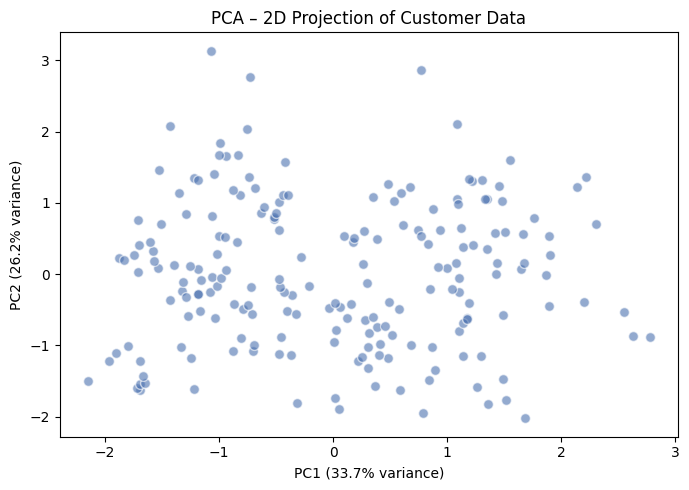


PC1 loadings: [ 0.23430156  0.68790025 -0.00608217 -0.68691996]
PC2 loadings: [ 0.62688553 -0.10368955  0.7652519   0.10321115]


In [8]:
# 1.3 – PCA 2-component projection scatter plot
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_pca[:, 0], X_pca[:, 1],
           alpha=0.6, color='#4C72B0', edgecolors='white', s=50)
ax.set_xlabel(f'PC1 ({ev[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({ev[1]*100:.1f}% variance)')
ax.set_title('PCA – 2D Projection of Customer Data')
plt.tight_layout()
plt.show()

print(f"\nPC1 loadings: {pca2.components_[0]}")
print(f"PC2 loadings: {pca2.components_[1]}")


## Task 2 – Clustering
### 2.1 Feature Selection and Scaling

In [9]:
# 2.1 – Select features and scale for clustering
# Annual Income and Spending Score show the most distinct cluster structure
from sklearn.preprocessing import StandardScaler

features = ['Annual Income (k$)', 'Spending Score (1-100)']
X_cluster = df[features].values

scaler2 = StandardScaler()
X2 = scaler2.fit_transform(X_cluster)

print("Feature matrix shape:", X2.shape)
print("Mean (should be ~0):", X2.mean(axis=0).round(5))
print("Std  (should be ~1):", X2.std(axis=0).round(5))


Feature matrix shape: (200, 2)
Mean (should be ~0): [-0. -0.]
Std  (should be ~1): [1. 1.]


### 2.2 K-Means Clustering

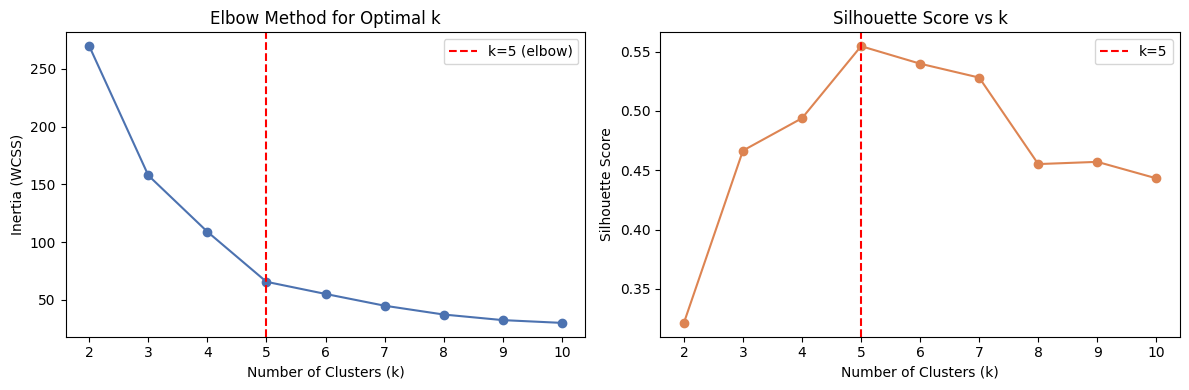

Silhouette scores:
  k=2: 0.3213
  k=3: 0.4666
  k=4: 0.4939
  k=5: 0.5547
  k=6: 0.5399
  k=7: 0.5281
  k=8: 0.4552
  k=9: 0.4571
  k=10: 0.4432


In [10]:
# 2.2 – Elbow method and Silhouette score to find optimal k
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

inertias, silhouettes = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X2)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X2, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_range, inertias, marker='o', color='#4C72B0')
axes[0].axvline(5, color='red', linestyle='--', label='k=5 (elbow)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method for Optimal k')
axes[0].legend()

axes[1].plot(K_range, silhouettes, marker='o', color='#DD8452')
axes[1].axvline(5, color='red', linestyle='--', label='k=5')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs k')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, s in zip(K_range, silhouettes):
    print(f"  k={k}: {s:.4f}")


K-Means (k=5) – Silhouette Score: 0.5547
K-Means (k=5) – Davies-Bouldin Score: 0.5722


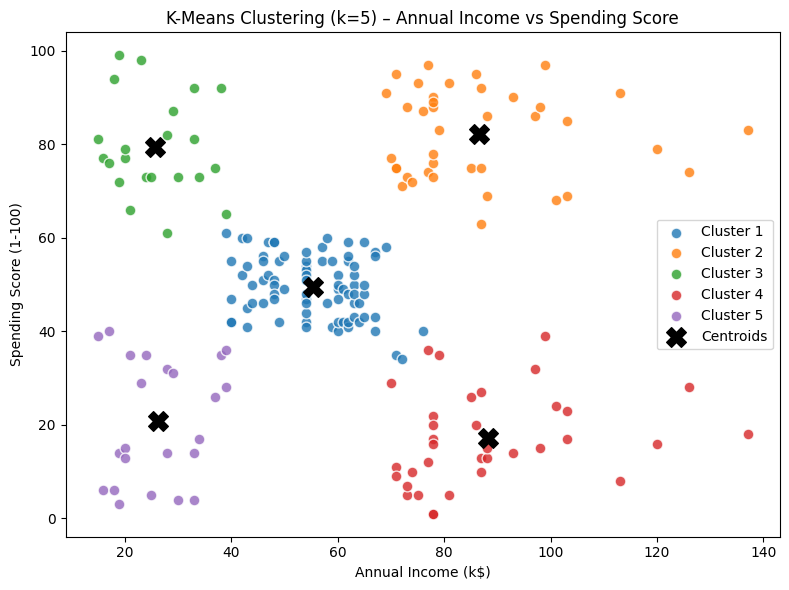

Cluster 1: 81 customers
Cluster 2: 39 customers
Cluster 3: 22 customers
Cluster 4: 35 customers
Cluster 5: 23 customers


In [11]:
# 2.2 – Fit K-Means with k=5 and visualise
import matplotlib.pyplot as plt

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X2)

km_sil = silhouette_score(X2, km_labels)
km_db  = davies_bouldin_score(X2, km_labels)
print(f"K-Means (k=5) – Silhouette Score: {km_sil:.4f}")
print(f"K-Means (k=5) – Davies-Bouldin Score: {km_db:.4f}")

palette = plt.cm.tab10.colors
centres_inv = scaler2.inverse_transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(figsize=(8, 6))
for i in range(5):
    mask = km_labels == i
    ax.scatter(df['Annual Income (k$)'][mask], df['Spending Score (1-100)'][mask],
               label=f'Cluster {i+1}', alpha=0.8, s=60, color=palette[i], edgecolors='white')
ax.scatter(centres_inv[:, 0], centres_inv[:, 1],
           c='black', marker='X', s=200, zorder=5, label='Centroids')
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('K-Means Clustering (k=5) – Annual Income vs Spending Score')
ax.legend()
plt.tight_layout()
plt.show()

# Print cluster sizes
for i in range(5):
    print(f"Cluster {i+1}: {(km_labels==i).sum()} customers")


### 2.3 DBSCAN Clustering

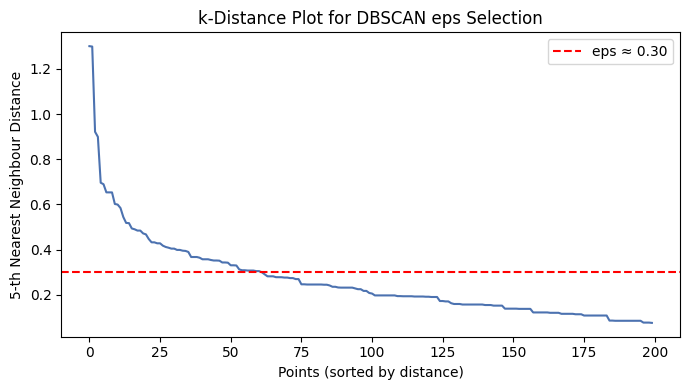

In [12]:
# 2.3 – k-distance plot to select eps for DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples = 5
nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X2)
dists, _ = nbrs.kneighbors(X2)
k_dists = np.sort(dists[:, min_samples-1])[::-1]  # distance to 4th nearest neighbour

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(k_dists)), k_dists, color='#4C72B0')
ax.axhline(0.30, color='red', linestyle='--', label='eps ≈ 0.30')
ax.set_xlabel('Points (sorted by distance)')
ax.set_ylabel(f'{min_samples}-th Nearest Neighbour Distance')
ax.set_title('k-Distance Plot for DBSCAN eps Selection')
ax.legend()
plt.tight_layout()
plt.show()


DBSCAN: 7 clusters found, 35 noise points
DBSCAN – Silhouette Score (excluding noise): 0.5243
DBSCAN – Davies-Bouldin Score (excluding noise): 0.5800


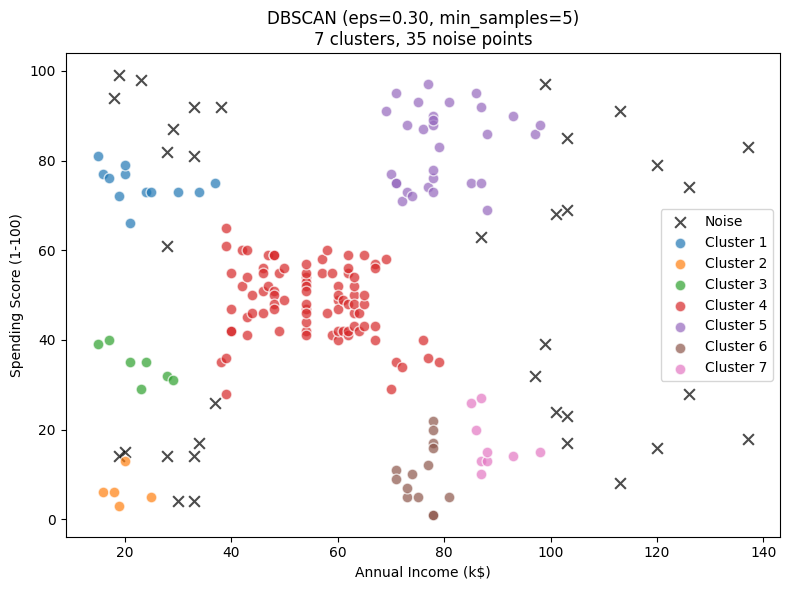

In [13]:
# 2.3 – Fit DBSCAN and visualise

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt

# Fit DBSCAN
db = DBSCAN(eps=0.30, min_samples=5)
db_labels = db.fit_predict(X2)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()

print(f"DBSCAN: {n_clusters_db} clusters found, {n_noise} noise points")

if n_clusters_db > 1:
    core_mask = db_labels != -1

    db_sil = silhouette_score(X2[core_mask], db_labels[core_mask])
    db_db = davies_bouldin_score(X2[core_mask], db_labels[core_mask])

    print(f"DBSCAN – Silhouette Score (excluding noise): {db_sil:.4f}")
    print(f"DBSCAN – Davies-Bouldin Score (excluding noise): {db_db:.4f}")

# Visualisation
fig, ax = plt.subplots(figsize=(8, 6))

unique_labels = sorted(set(db_labels))

for lbl in unique_labels:
    mask = db_labels == lbl

    # Label name
    if lbl == -1:
        label = 'Noise'
        color = 'black'
        marker = 'x'
    else:
        label = f'Cluster {lbl + 1}'
        color = palette[lbl % 10]
        marker = 'o'

    ax.scatter(
        df['Annual Income (k$)'][mask],
        df['Spending Score (1-100)'][mask],
        label=label,
        alpha=0.7,
        s=60,
        color=color,
        marker=marker,
        edgecolors='white'
    )

# Labels and title
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')

ax.set_title(
    f'DBSCAN (eps=0.30, min_samples=5)\n'
    f'{n_clusters_db} clusters, {n_noise} noise points'
)

ax.legend()

plt.tight_layout()
plt.show()


### 2.4 Algorithm Comparison

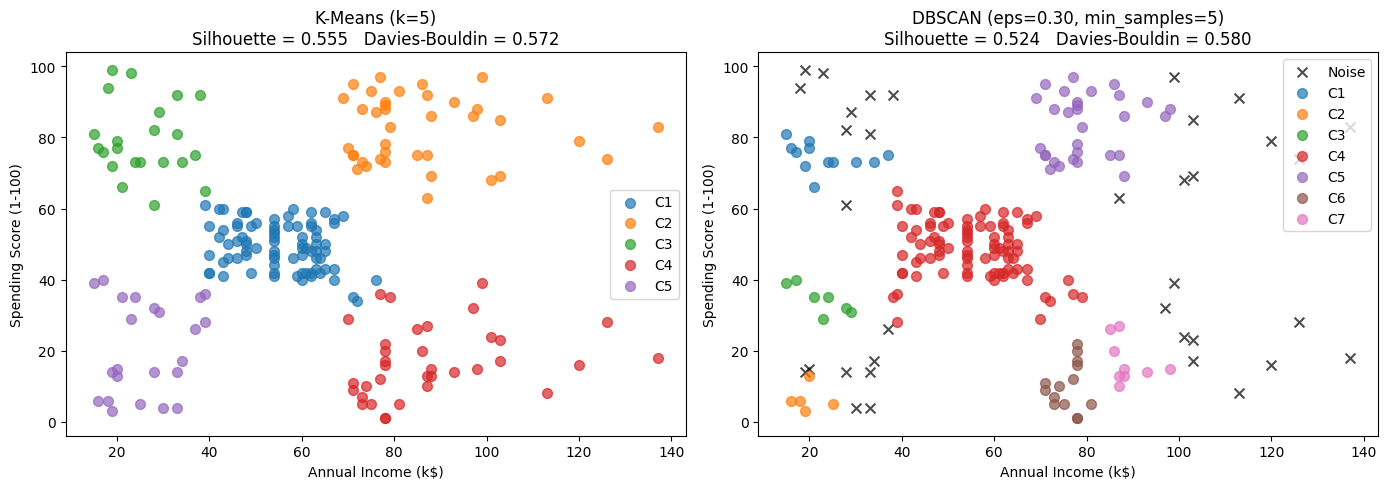

,Algorithm,Clusters Found,Noise Points,Silhouette Score,Davies-Bouldin Score
0,K-Means (k=5),5,0,0.5547,0.5722
1,"DBSCAN (eps=0.30, min_s=5)",7,35,0.5243,0.5800


In [14]:
# 2.4 – Side-by-side comparison of K-Means and DBSCAN

import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means Plot
for i in range(5):
    mask = km_labels == i

    axes[0].scatter(
        df['Annual Income (k$)'][mask],
        df['Spending Score (1-100)'][mask],
        label=f'C{i+1}',
        alpha=0.7,
        s=50,
        color=palette[i]
    )

axes[0].set_title(
    f'K-Means (k=5)\n'
    f'Silhouette = {km_sil:.3f}   Davies-Bouldin = {km_db:.3f}'
)

axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].legend()

# DBSCAN Plot
for lbl in sorted(set(db_labels)):

    mask = db_labels == lbl

    color = 'black' if lbl == -1 else palette[lbl % 10]
    name = 'Noise' if lbl == -1 else f'C{lbl+1}'
    marker = 'x' if lbl == -1 else 'o'

    axes[1].scatter(
        df['Annual Income (k$)'][mask],
        df['Spending Score (1-100)'][mask],
        label=name,
        alpha=0.7,
        s=50,
        color=color,
        marker=marker
    )

axes[1].set_title(
    f'DBSCAN (eps=0.30, min_samples=5)\n'
    f'Silhouette = {db_sil:.3f}   Davies-Bouldin = {db_db:.3f}'
)

axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].legend()

# Layout
plt.tight_layout()
plt.show()

# Summary Table
summary = {
    'Algorithm': [
        'K-Means (k=5)',
        'DBSCAN (eps=0.30, min_s=5)'
    ],
    'Clusters Found': [
        5,
        n_clusters_db
    ],
    'Noise Points': [
        0,
        n_noise
    ],
    'Silhouette Score': [
        round(km_sil, 4),
        round(db_sil, 4)
    ],
    'Davies-Bouldin Score': [
        round(km_db, 4),
        round(db_db, 4)
    ],
}

display(pd.DataFrame(summary))